In [1]:
# 1️⃣ Import required libraries
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, 
    ConfusionMatrixDisplay, roc_auc_score, precision_recall_curve, 
    auc, roc_curve
)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import matplotlib.pyplot as plt


In [2]:
# 2️⃣ Load the diabetes dataset
df = pd.read_csv('data/diabetes.csv')
print("Dataset loaded successfully!")
print(f"Shape: {df.shape}")
df.head()

Dataset loaded successfully!
Shape: (769, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# 3️⃣ Basic Information
print("Dataset Info:")
df.info()
print("\n" + "="*50 + "\n")
print("Statistical Summary:")
df.describe()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 769 entries, 0 to 768
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               769 non-null    int64  
 1   Glucose                   769 non-null    int64  
 2   BloodPressure             769 non-null    int64  
 3   SkinThickness             769 non-null    int64  
 4   Insulin                   769 non-null    int64  
 5   BMI                       769 non-null    float64
 6   DiabetesPedigreeFunction  769 non-null    float64
 7   Age                       769 non-null    int64  
 8   Outcome                   769 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.2 KB


Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000
mean,3.840052,120.897269,69.115735,20.509753,79.697009,31.998179,0.471590,33.269181,0.349805
std,3.370237,31.951886,19.345296,15.959020,115.203999,7.880557,0.331208,11.778737,0.477219
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.244000,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,29.000000,32.000000,0.371000,29.000000,0.000000
75%,6.000000,140.000000,80.000000,32.000000,127.000000,36.600000,0.626000,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
# 4️⃣ Check for missing values and duplicates
print("Missing Values:")
print(df.isnull().sum())
print(f"\nDuplicates: {df.duplicated().sum()}")

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicates: 0


C:\Users\tsinn\AppData\Local\Temp\ipykernel_12708\452630657.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df[col] for col in columns_to_plot],


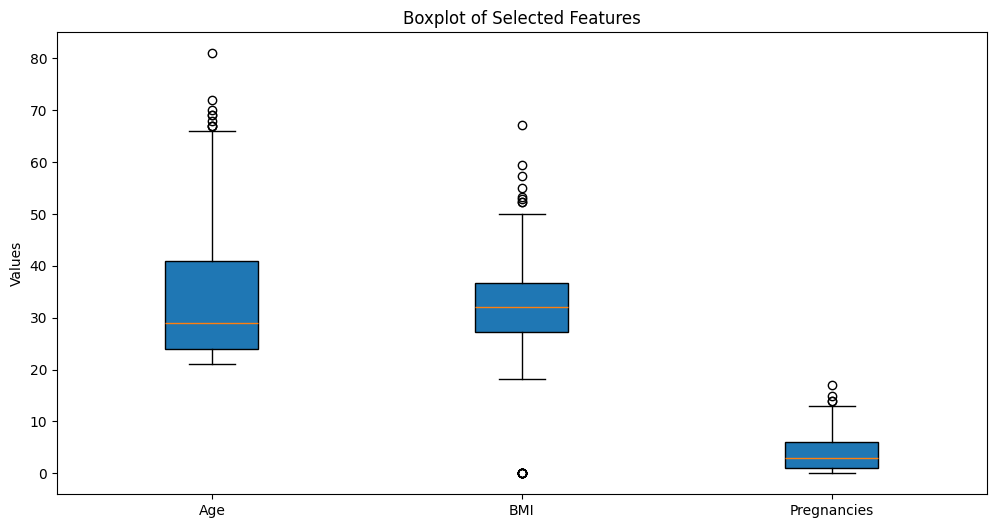

In [5]:
# 5️⃣ Boxplot to detect outliers
columns_to_plot = ['Age', 'BMI', 'Pregnancies']
plt.figure(figsize=(12,6))
plt.boxplot([df[col] for col in columns_to_plot], 
            labels=columns_to_plot, patch_artist=True, showfliers=True)
plt.title('Boxplot of Selected Features')
plt.ylabel('Values')
plt.show()

Class Distribution:
Outcome
0    500
1    269
Name: count, dtype: int64

Imbalance Ratio: 1.86:1


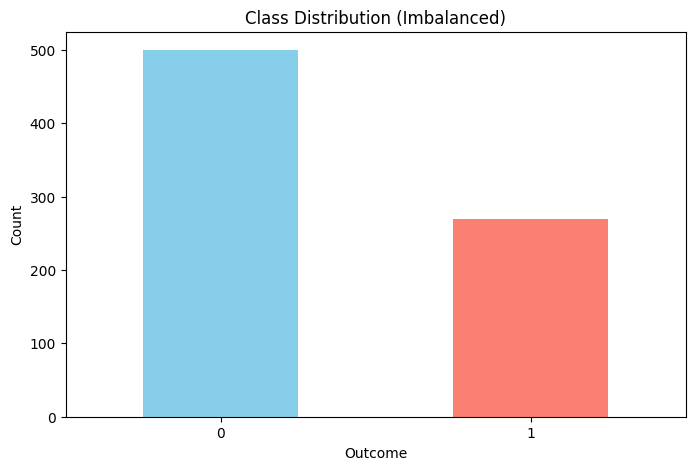

In [6]:
# 6️⃣ Check class imbalance (IMPORTANT!)
print("Class Distribution:")
print(df['Outcome'].value_counts())
print(f"\nImbalance Ratio: {df['Outcome'].value_counts()[0] / df['Outcome'].value_counts()[1]:.2f}:1")

# Visualize
plt.figure(figsize=(8,5))
df['Outcome'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Class Distribution (Imbalanced)')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

C:\Users\tsinn\AppData\Local\Temp\ipykernel_12708\790498595.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_counts = df.groupby(['Age_group', 'Outcome']).size().unstack(fill_value=0)


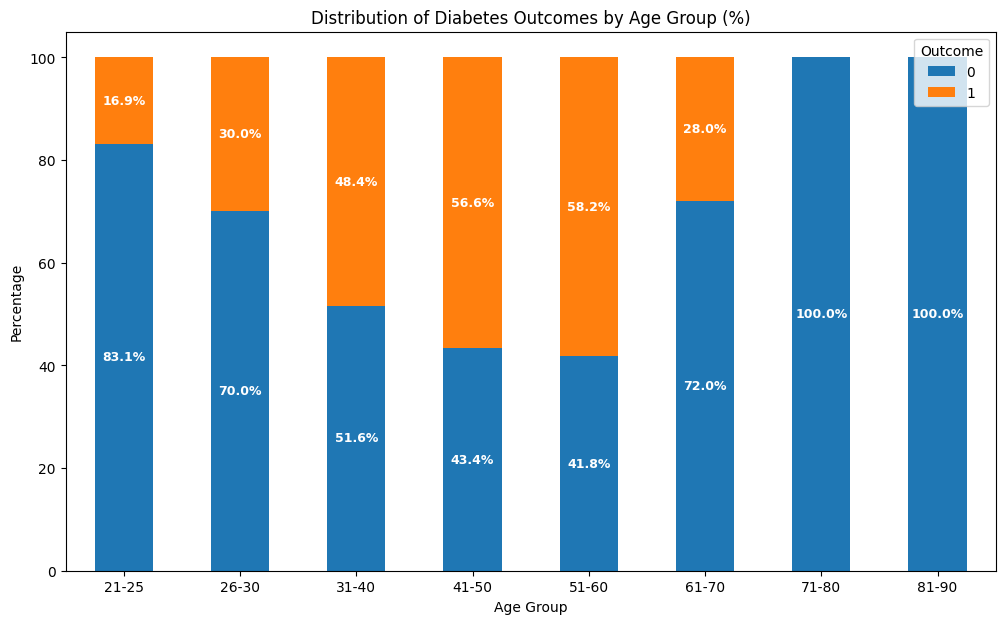

In [7]:
# 7️⃣ Create Age Groups
bins = [20, 25, 30, 40, 50, 60, 70, 80, 90]
labels = ['21-25','26-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90']
df['Age_group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

# Gruppieren nach Outcome und Age_group
age_counts = df.groupby(['Age_group', 'Outcome']).size().unstack(fill_value=0)

# In Prozent umrechnen
age_percent = age_counts.div(age_counts.sum(axis=1), axis=0) * 100

# Plot
ax = age_percent.plot(kind='bar', figsize=(12,7), stacked=True)

# Prozentwerte auf den Balken anzeigen
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%', 
                    (p.get_x() + p.get_width() / 2., p.get_y() + height / 2.),
                    ha='center', va='center', fontsize=9, color='white', fontweight='bold')

plt.title('Distribution of Diabetes Outcomes by Age Group (%)')
plt.ylabel('Percentage')
plt.xlabel('Age Group')
plt.xticks(rotation=0)
plt.legend(title='Outcome')
plt.show()

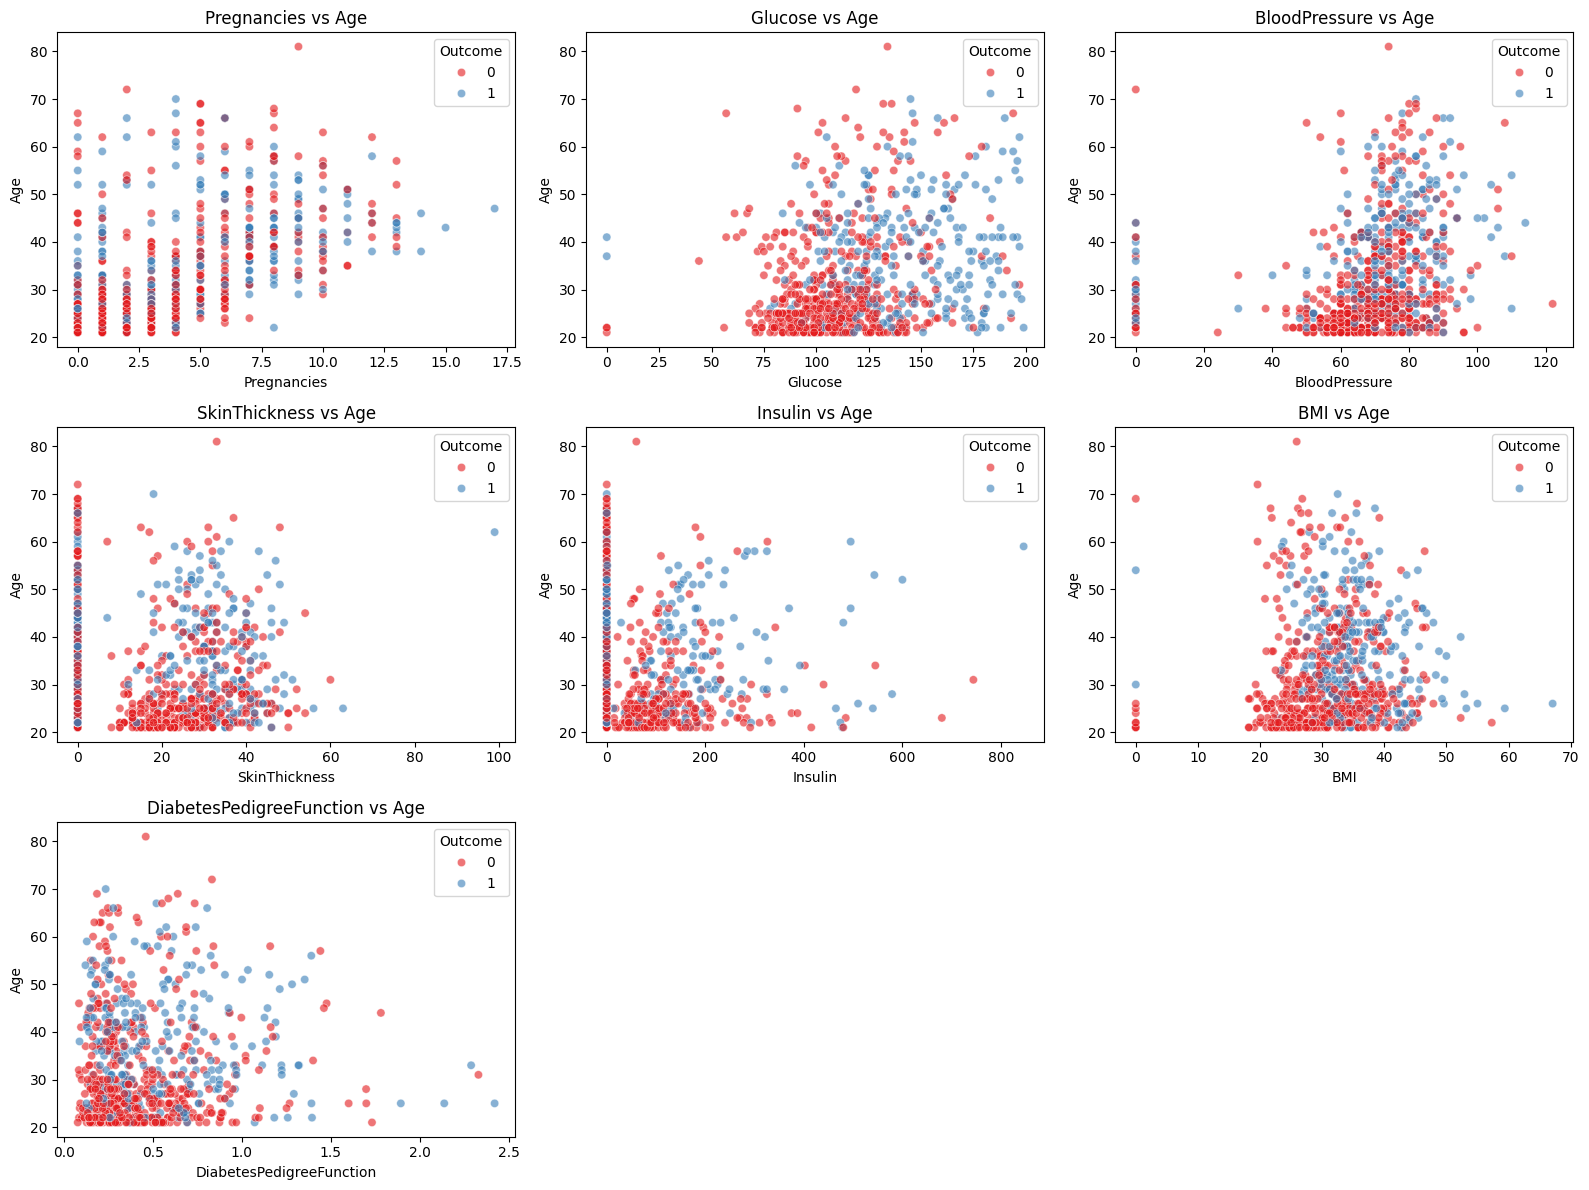

In [8]:
# 8️⃣ Feature vs Age Scatter Plots
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
            'Insulin', 'BMI', 'DiabetesPedigreeFunction']

plt.figure(figsize=(16,12))

for i, col in enumerate(features):
    plt.subplot(3, 3, i+1)
    sns.scatterplot(data=df, x=col, y='Age', hue='Outcome', palette='Set1', alpha=0.6)
    plt.title(f'{col} vs Age')

plt.tight_layout()
plt.show()

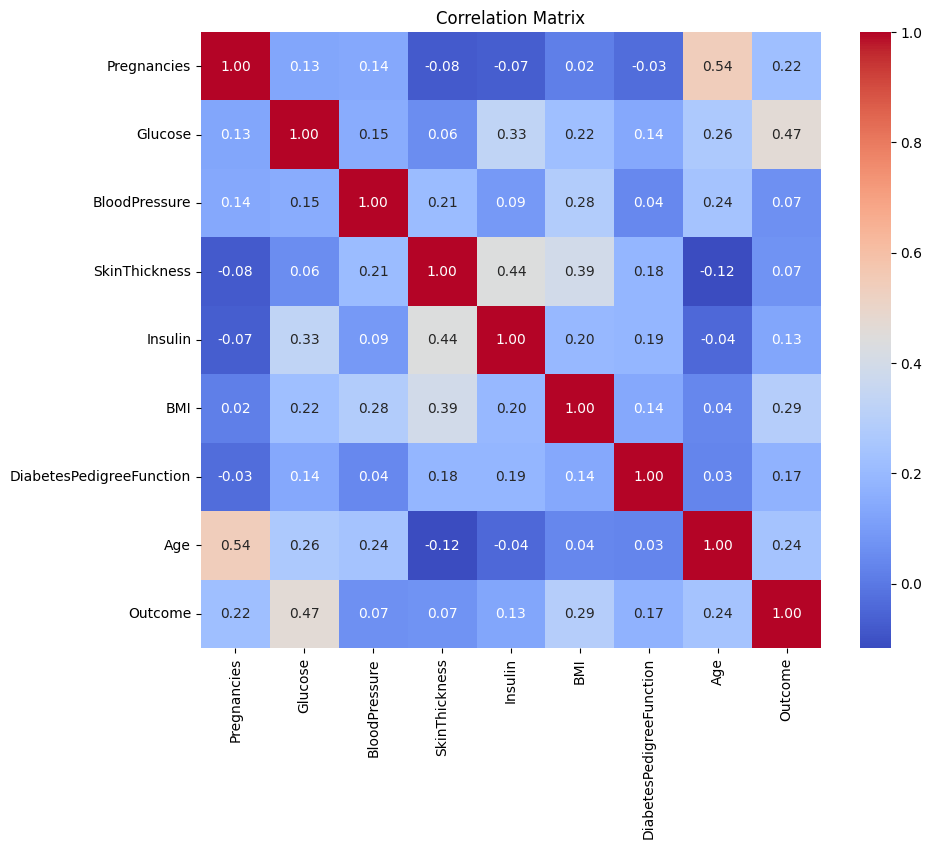

In [9]:
# 9️⃣ Correlation Matrix
numeric_df = df.select_dtypes(include=['number'])

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [10]:
# 🔟 Prepare data for modeling
# Convert Age_group to numeric
df['Age_group'] = df['Age_group'].cat.codes

# Convert Outcome to category
df['Outcome'] = df['Outcome'].astype('category')

print("Data types after conversion:")
print(df.dtypes)

Data types after conversion:
Pregnancies                    int64
Glucose                        int64
BloodPressure                  int64
SkinThickness                  int64
Insulin                        int64
BMI                          float64
DiabetesPedigreeFunction     float64
Age                            int64
Outcome                     category
Age_group                       int8
dtype: object


In [11]:
# 1️⃣1️⃣ Split data
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")

Training set size: (615, 9)
Test set size: (154, 9)


🔄 Applying SMOTE...

Before SMOTE:
Class distribution: Outcome
0    400
1    215
Name: count, dtype: int64
Imbalance ratio: 1.86:1

After SMOTE:
Class distribution: Outcome
0    400
1    400
Name: count, dtype: int64
Balance ratio: 1.00:1


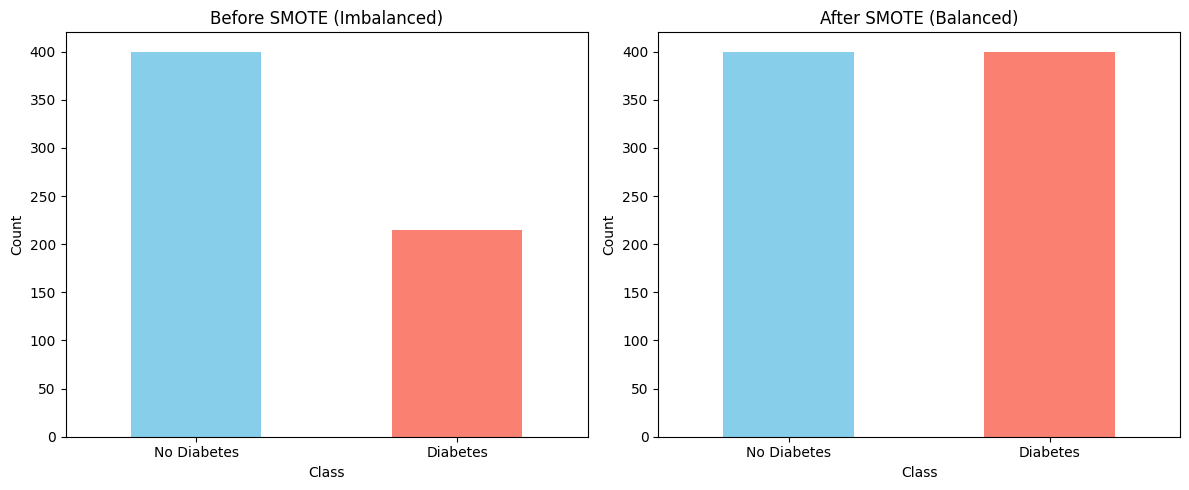

In [12]:
# 1️⃣2️⃣ Apply SMOTE to handle class imbalance
print("🔄 Applying SMOTE...")
print("\nBefore SMOTE:")
print(f"Class distribution: {y_train.value_counts()}")
print(f"Imbalance ratio: {y_train.value_counts()[0] / y_train.value_counts()[1]:.2f}:1")

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\nAfter SMOTE:")
print(f"Class distribution: {pd.Series(y_train_smote).value_counts()}")
print(f"Balance ratio: {pd.Series(y_train_smote).value_counts()[0] / pd.Series(y_train_smote).value_counts()[1]:.2f}:1")

# Visualize Before/After
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

y_train.value_counts().plot(kind='bar', ax=axes[0], color=['skyblue', 'salmon'])
axes[0].set_title('Before SMOTE (Imbalanced)')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Class')
axes[0].set_xticklabels(['No Diabetes', 'Diabetes'], rotation=0)

pd.Series(y_train_smote).value_counts().plot(kind='bar', ax=axes[1], color=['skyblue', 'salmon'])
axes[1].set_title('After SMOTE (Balanced)')
axes[1].set_ylabel('Count')
axes[1].set_xlabel('Class')
axes[1].set_xticklabels(['No Diabetes', 'Diabetes'], rotation=0)

plt.tight_layout()
plt.show()

In [13]:
# 1️⃣3️⃣ Train XGBoost with SMOTE-balanced data
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

print("Training model with SMOTE-balanced data...")
model.fit(X_train_smote, y_train_smote)
print("✅ Model trained successfully!")

Training model with SMOTE-balanced data...
✅ Model trained successfully!


In [14]:
# 1️⃣4️⃣ Make predictions
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


In [15]:
# 1️⃣5️⃣ Basic Evaluation Metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7662

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.78      0.81       100
           1       0.65      0.74      0.69        54

    accuracy                           0.77       154
   macro avg       0.75      0.76      0.75       154
weighted avg       0.78      0.77      0.77       154


Confusion Matrix:
[[78 22]
 [14 40]]


In [22]:
# 1️⃣7️⃣ Medical-focused metrics
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
precision_score = tp / (tp + fp)  # ← Umbenennen!

print(f"🏥 Medical Metrics:")
print(f"   Sensitivity / Recall (catching real diabetics): {sensitivity:.3f}")
print(f"   Specificity (correctly identifying healthy):     {specificity:.3f}")
print(f"   Precision (when model says diabetes, it's right): {precision_score:.3f}")


🏥 Medical Metrics:
   Sensitivity / Recall (catching real diabetics): 0.741
   Specificity (correctly identifying healthy):     0.780
   Precision (when model says diabetes, it's right): 0.645


ROC-AUC Score: 0.8326


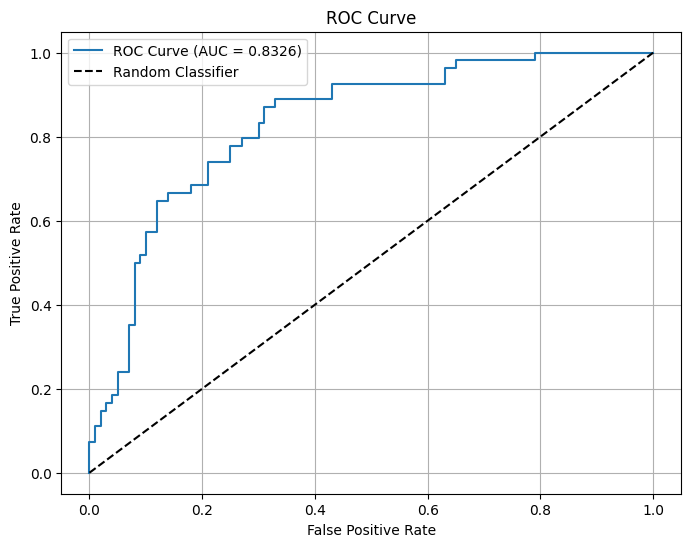

In [17]:
# 1️⃣8️⃣ ROC-AUC Score and Curve
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

Best F1-score threshold: 0.272
Best F1-score: 0.712


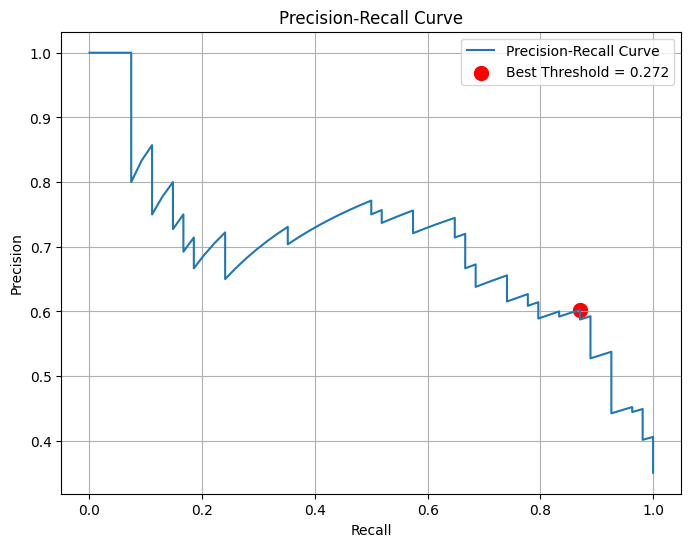

In [18]:
# 1️⃣9️⃣ Find optimal threshold
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)
f1_scores = 2 * recall * precision / (recall + precision + 1e-10)
best_threshold_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_idx]
best_f1 = np.max(f1_scores)

print(f"Best F1-score threshold: {best_threshold:.3f}")
print(f"Best F1-score: {best_f1:.3f}")

# Plot Precision-Recall Curve
plt.figure(figsize=(8,6))
plt.plot(recall, precision, label='Precision-Recall Curve')
plt.scatter(recall[best_threshold_idx], precision[best_threshold_idx], 
            color='red', s=100, label=f'Best Threshold = {best_threshold:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

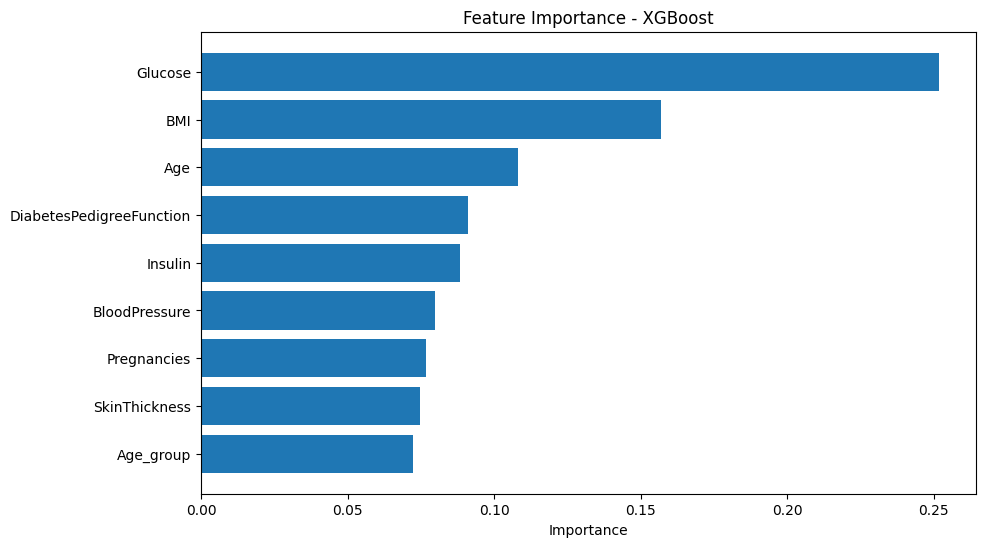


Top 5 Most Important Features:
                    feature  importance
1                   Glucose    0.251820
5                       BMI    0.156796
7                       Age    0.108101
6  DiabetesPedigreeFunction    0.090997
4                   Insulin    0.088425


In [19]:
# 2️⃣0️⃣ Feature Importance
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(feature_importance['feature'], feature_importance['importance'])
plt.xlabel('Importance')
plt.title('Feature Importance - XGBoost')
plt.gca().invert_yaxis()
plt.show()

print("\nTop 5 Most Important Features:")
print(feature_importance.head())


In [20]:
# 2️⃣1️⃣ Test with real-world samples
test_data = pd.DataFrame({
    'Pregnancies': [1, 8, 4, 10, 1, 8, 1, 5, 4, 9],
    'Glucose': [89, 125, 110, 168, 139, 197, 189, 166, 129, 119],
    'BloodPressure': [66, 96, 92, 74, 62, 74, 60, 72, 86, 80],
    'SkinThickness': [23, 0, 0, 0, 41, 0, 23, 19, 20, 35],
    'Insulin': [94, 0, 0, 0, 480, 0, 846, 175, 270, 0],
    'BMI': [28.1, 15.8, 37.6, 38.0, 40.7, 25.9, 30.1, 25.8, 35.1, 29.0],
    'DiabetesPedigreeFunction': [0.167, 0.232, 0.191, 0.537, 0.536, 1.191, 0.398, 0.587, 0.231, 0.263],
    'Age': [21, 54, 30, 34, 21, 39, 59, 51, 23, 29],
    'Age_group': [0, 2, 1, 1, 0, 1, 2, 2, 0, 0]
})

predictions = model.predict(test_data)
probabilities = model.predict_proba(test_data)[:, 1]

test_data['Predicted_Outcome'] = predictions
test_data['Diabetes_Probability (%)'] = (probabilities * 100).round(1)

print("Real-World Test Predictions:")
print(test_data[['Age', 'BMI', 'Glucose', 'Predicted_Outcome', 'Diabetes_Probability (%)']])

Real-World Test Predictions:
   Age   BMI  Glucose  Predicted_Outcome  Diabetes_Probability (%)
0   21  28.1       89                  0                  0.700000
1   54  15.8      125                  1                 74.699997
2   30  37.6      110                  0                 13.700000
3   34  38.0      168                  1                 96.500000
4   21  40.7      139                  1                 75.099998
5   39  25.9      197                  1                 81.900002
6   59  30.1      189                  1                 95.699997
7   51  25.8      166                  1                 93.900002
8   23  35.1      129                  0                  4.500000
9   29  29.0      119                  1                 93.800003


In [24]:
# 2️⃣2️⃣ Final Summary
print("="*60)
print("🎯 DIABETES PREDICTION MODEL - FINAL RESULTS")
print("="*60)
print(f"\n📊 Model: XGBoost Classifier with SMOTE")
print(f"📈 Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"📈 ROC-AUC Score: {roc_auc:.4f}")
print(f"🎯 Best F1-Score: {best_f1:.3f} (at threshold {best_threshold:.3f})")
print(f"\n🏥 Medical Metrics:")
print(f"   Sensitivity: {sensitivity:.3f}")
print(f"   Specificity: {specificity:.3f}")
print(f"   Precision: {precision_score:.3f}")  # ← Geändert!
print(f"\n✅ Model ready for deployment!")
print("="*60)

🎯 DIABETES PREDICTION MODEL - FINAL RESULTS

📊 Model: XGBoost Classifier with SMOTE
📈 Accuracy: 0.7662
📈 ROC-AUC Score: 0.8326
🎯 Best F1-Score: 0.712 (at threshold 0.272)

🏥 Medical Metrics:
   Sensitivity: 0.741
   Specificity: 0.780
   Precision: 0.645

✅ Model ready for deployment!
